In [1]:
import pandas as pd
import numpy as np

In [2]:
# Load dataset
df = pd.read_csv(
    "https://raw.githubusercontent.com/DataTalksClub/machine-learning-zoomcamp/main/cohorts/2026/data/car_fuel_efficiency_2026.csv"
)

**Preparing the dataset**

---


Use only the following columns:

'engine_displacement',
'horsepower',
'vehicle_weight',
'model_year',
'fuel_efficiency_mpg'




In [3]:
# Keep only the required columns
features = [
    "engine_displacement",
    "horsepower",
    "vehicle_weight",
    "model_year"
]

target = "fuel_efficiency_mpg"

df = df[features + [target]]

print(df.shape)

(10000, 5)


In [4]:
df["fuel_efficiency_mpg"].describe()

count    10000.000000
mean        29.997700
std          2.930245
min         19.800000
25%         28.000000
50%         30.000000
75%         31.900000
max         41.200000
Name: fuel_efficiency_mpg, dtype: float64

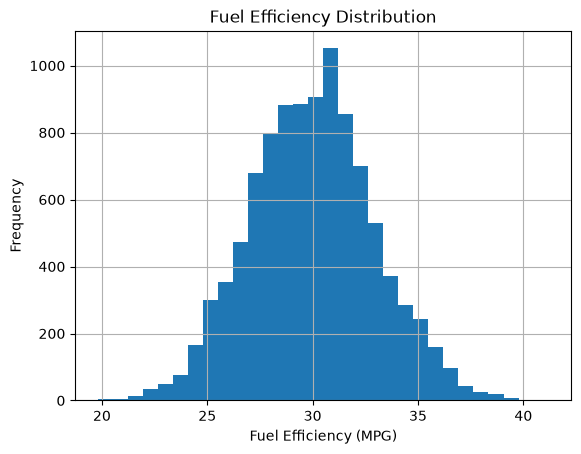

In [5]:
import matplotlib.pyplot as plt

df["fuel_efficiency_mpg"].hist(bins=30)

plt.xlabel("Fuel Efficiency (MPG)")
plt.ylabel("Frequency")
plt.title("Fuel Efficiency Distribution")
plt.show()

EDA
Look at the fuel_efficiency_mpg variable. Does it have a long tail?


---


# Question 1
### There's one column with missing values. What is it?

'engine_displacement' ,
'horsepower',
'vehicle_weight',

'model_year'

In [6]:
df.isnull().sum()

engine_displacement      0
horsepower             877
vehicle_weight           0
model_year               0
fuel_efficiency_mpg      0
dtype: int64

In [7]:
#I can do this also
missing_column = df.columns[df.isna().any()][0]
missing_column

'horsepower'

# **Question 2**


---
## What's the median (50% percentile) for variable 'horsepower'?

204,
254,
304,
354

In [8]:
df["horsepower"].median()

np.float64(254.0)

Prepare and split the dataset
---
Shuffle the filtered dataset and create the split exactly as in the lecture:

In [9]:
n = len(df)

n_val = int(n * 0.2)
n_test = int(n * 0.2)
n_train = n - n_val - n_test

np.random.seed(42)

idx = np.arange(n)
np.random.shuffle(idx)

df_train = df.iloc[idx[:n_train]]
df_val = df.iloc[idx[n_train:n_train + n_val]]
df_test = df.iloc[idx[n_train + n_val:]]

print(len(df_train))
print(len(df_val))
print(len(df_test))

6000
2000
2000


Linear Regression function


---


For the homework, we can implement linear regression ourselves as in the lecture.

In [10]:
def train_linear_regression(X, y, r=0):

    X = np.column_stack([
        np.ones(len(X)),
        X
    ])

    XTX = X.T @ X

    reg = r * np.eye(XTX.shape[0])

    # Don't regularize the intercept
    reg[0, 0] = 0

    XTX_reg = XTX + reg

    w = np.linalg.solve(
        XTX_reg,
        X.T @ y
    )

    return w

In [11]:
#RMSE
def rmse(y, y_pred):
    error = y_pred - y
    mse = np.mean(error ** 2)
    return np.sqrt(mse)

# Question 3
---
Question 3
We need to deal with missing values for the column from Q1.
We have two options: fill it with 0 or with the mean of this variable.
Try both options. For each, train a linear regression model without regularization using the code from the lessons.
For computing the mean, use the training only!
Use the validation dataset to evaluate the models and compare the RMSE of each option.
Round the RMSE scores to 3 decimal digits using round(score, 3). This keeps the imputation difference visible in this release.


---


Which option gives better RMSE?
Options:

With 0 ,
With mean,
Both are equally good

In [12]:
X_train = df_train[features]
y_train = df_train[target]

X_val = df_val[features]
y_val = df_val[target]

**Fill with 0**

In [13]:
X_train_0 = X_train.fillna(0)
X_val_0 = X_val.fillna(0)

w = train_linear_regression(
    X_train_0,
    y_train,
    r=0
)

X_val_matrix = np.column_stack([
    np.ones(len(X_val_0)),
    X_val_0
])

y_pred = X_val_matrix @ w

score_0 = rmse(
    y_val,
    y_pred
)

print("RMSE with 0:", round(score_0, 3))

RMSE with 0: 2.205


**Fill with training mean**

calculate the mean


In [14]:
horsepower_mean = X_train["horsepower"].mean()

print(" mean:", horsepower_mean)

 mean: 254.46338337605272


In [15]:
X_train_mean = X_train.fillna(horsepower_mean)
X_val_mean = X_val.fillna(horsepower_mean)

w = train_linear_regression(
    X_train_mean,
    y_train,
    r=0
)

X_val_matrix = np.column_stack([
    np.ones(len(X_val_mean)),
    X_val_mean
])

y_pred = X_val_matrix @ w

score_mean = rmse(
    y_val,
    y_pred
)

print("RMSE with mean:", round(score_mean, 3))

RMSE with mean: 2.202


Option 1 — Fill with 0: RMSE = 2.205



Option 2 — Fill with mean: RMSE = 2.202

Since 2.202 < 2.205, the better option is:With mean


---

 Q3: With mean

Now let's train a regularized linear regression.
For this question, fill the NAs with 0.
Try different values of r from this list: [0, 0.01, 0.1, 1, 5, 10, 100].
Use RMSE to evaluate the model on the validation dataset.
Round the RMSE scores to 4 decimal digits. This keeps the small but real regularization differences visible instead of turning several choices into a tie.
Which r gives the best RMSE?
If multiple options give the same best RMSE, select the smallest r.

Question 4 — Regularization


---


Now the homework says: Fill NAs with 0.

In [16]:
X_train = df_train[features].fillna(0)
y_train = df_train[target]

X_val = df_val[features].fillna(0)
y_val = df_val[target]

In [17]:
r_values = [0, 0.01, 0.1, 1, 5, 10, 100]

scores = {}

for r in r_values:

    w = train_linear_regression(
        X_train,
        y_train,
        r=r
    )

    X_val_matrix = np.column_stack([
        np.ones(len(X_val)),
        X_val
    ])

    y_pred = X_val_matrix @ w

    score = rmse(y_val, y_pred)

    scores[r] = score

    print(f"r = {r:<5} RMSE = {score:.10f}")



r = 0     RMSE = 2.2052931948
r = 0.01  RMSE = 2.2052931948
r = 0.1   RMSE = 2.2052931952
r = 1     RMSE = 2.2052931993
r = 5     RMSE = 2.2052932176
r = 10    RMSE = 2.2052932404
r = 100   RMSE = 2.2052936541


In [18]:
best_r = min(
    r_values,
    key=lambda r: (round(scores[r], 4), r)
)

print("Best r:", best_r)

Best r: 0


Question 5
We used seed 42 for splitting the data. Let's find out how selecting the seed influences our score.
Try different seed values: [0, 1, 2, 3, 4, 5, 6, 7, 8, 9].
For each seed, do the train/validation/test split with 60%/20%/20% distribution.
Fill the missing values with 0 and train a model without regularization.
For each seed, evaluate the model on the validation dataset and collect the RMSE scores.
What's the standard deviation of all the scores? To compute the standard deviation, use np.std.
Round the result to 3 decimal digits (round(std, 3))
What's the value of std?

0.006
0.016
0.029
0.036

In [19]:
scores = []

for seed in range(10):

    # -------------------------
    # Split
    # -------------------------

    n = len(df)

    n_val = int(n * 0.2)
    n_test = int(n * 0.2)
    n_train = n - n_val - n_test

    np.random.seed(seed)

    idx = np.arange(n)
    np.random.shuffle(idx)

    train = df.iloc[idx[:n_train]]
    val = df.iloc[idx[n_train:n_train + n_val]]

    # -------------------------
    # Prepare data
    # -------------------------

    X_train = train[features].fillna(0)
    y_train = train[target]

    X_val = val[features].fillna(0)
    y_val = val[target]

    # -------------------------
    # Train
    # -------------------------

    w = train_linear_regression(
        X_train,
        y_train,
        r=0
    )

    # -------------------------
    # Predict
    # -------------------------

    X_val_matrix = np.column_stack([
        np.ones(len(X_val)),
        X_val
    ])

    y_pred = X_val_matrix @ w

    # -------------------------
    # RMSE
    # -------------------------

    score = rmse(
        y_val,
        y_pred
    )

    scores.append(score)

    print(
        f"seed = {seed}, RMSE = {score:.3f}"
    )

seed = 0, RMSE = 2.239
seed = 1, RMSE = 2.202
seed = 2, RMSE = 2.163
seed = 3, RMSE = 2.204
seed = 4, RMSE = 2.202
seed = 5, RMSE = 2.246
seed = 6, RMSE = 2.270
seed = 7, RMSE = 2.191
seed = 8, RMSE = 2.217
seed = 9, RMSE = 2.207


In [20]:
std = np.std(scores)

print("Standard deviation:", std)
print("Rounded:", round(std, 3))

Standard deviation: 0.02878127407820725
Rounded: 0.029


Question 6
Split the dataset like previously, use seed 9.
Combine train and validation datasets.
Fill the missing values with 0 and train a model with r=0.001.
What's the RMSE on the test dataset?
Options:

0.236
2.236
22.10
221.0

In [21]:
n = len(df)

n_val = int(n * 0.2)
n_test = int(n * 0.2)
n_train = n - n_val - n_test

np.random.seed(9)

idx = np.arange(n)
np.random.shuffle(idx)

df_train = df.iloc[idx[:n_train]]
df_val = df.iloc[idx[n_train:n_train + n_val]]
df_test = df.iloc[idx[n_train + n_val:]]

# Combine train + validation
df_full_train = pd.concat([
    df_train,
    df_val
])

print(len(df_full_train))
print(len(df_test))

# Prepare data
X_full_train = df_full_train[features].fillna(0)
y_full_train = df_full_train[target]

X_test = df_test[features].fillna(0)
y_test = df_test[target]

# Train with r = 0.001
w = train_linear_regression(
    X_full_train,
    y_full_train,
    r=0.001
)

# Predictions
X_test_matrix = np.column_stack([
    np.ones(len(X_test)),
    X_test
])

y_pred = X_test_matrix @ w

# RMSE
test_score = rmse(
    y_test,
    y_pred
)

print("Test RMSE:", test_score)
print("Rounded:", round(test_score, 3))

8000
2000
Test RMSE: 2.2357747028137953
Rounded: 2.236
